# Introduction

This notebook demonstrates how to use CNit with parameters calibrated to emulate 20 TRENDY-v11 dynamic global vegetation models (DGVMs).

The calibrated parameters, forcing data, and calibration targets are available from [CNit Model Calibration and Results](https://doi.org/10.5281/zenodo.18116573). Before running the notebook, place the following three data files in the project-level `data/` directory:

- **Calibrated parameters:** `cali_trendy_best_fitting.csv`
- **Forcing data:** `TRENDY_cali_forcing.nc` (S0–S3 CO₂, climate, land-use, and nitrogen-related inputs)
- **Calibration targets:** `TRENDY_cali_target.nc` (S0–S3 DGVM outputs)

This example notebook `CNit_example_TRENDY_DGVMs_emulation.ipynb` is in the project-level `notebooks/` directory.

TRENDY DGVM simulations contribute to the Global Carbon Budget by estimating the potential land carbon sink (SLAND) using the S2 simulation. They are also used to attribute net biome production (NBP) to environmental and anthropogenic drivers, including changes in atmospheric CO₂, climate, and land use. The S0–S3 experiments are designed to isolate the effects of these drivers:

- **S0:** All forcings are held at their pre-industrial levels.
- **S1:** Atmospheric CO₂ varies, while climate and land use remain at pre-industrial levels.
- **S2:** Atmospheric CO₂ and climate vary, while land use remains at pre-industrial levels.
- **S3:** Atmospheric CO₂, climate, and land use vary over the historical period.

For details on the TRENDY project and the S0–S3 experiments, see [TRENDY overview](https://doi.org/10.1029/2024GB008102).

# Import required libraries and modules

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from pathlib import Path

In [2]:
from cnit import CNitModel, CNitModelConfig, CNitExpConfig
from cnit import Q  # Local pint.quantity class for units handling

# Set default plotting properties

In [3]:
plt.rcParams.update(
    {
        "font.size": 6,  # Default font size for all text
        "axes.titlesize": 6,  # Axes title
        "axes.labelsize": 6,  # Axes labels
        "xtick.labelsize": 6,  # X-axis tick labels
        "ytick.labelsize": 6,  # Y-axis tick labels
        "legend.fontsize": 6,  # Legend text
        "figure.titlesize": 6,  # Figure title
        "lines.linewidth": 0.5,  # Default line width
        "figure.figsize": (9 / 2.54, 6 / 2.54),  # Default figure size in cm
        "figure.dpi": 150,  # Default DPI for figures
        "figure.constrained_layout.use": True,  # Use constrained layout by default
        "xtick.major.size": 1,  # X-axis major tick length
        "ytick.major.size": 1,  # Y-axis major tick length
    }
)

# Read forcing data and DGVM outputs

Place the TRENDY forcing, target, and calibration CSV files in the project-level
data/ directory. The path setup below also works when the notebook is run from
the notebooks/ directory.

In [4]:
# Locate the repository-level data directory when running from the project root
# or from notebooks/.
project_root = Path.cwd()
if not (project_root / "data").is_dir():
    project_root = project_root.parent
data_path = project_root / "data"
parameter_csv = data_path / "cali_trendy_best_fitting.csv"

In [5]:
forcing_data = xr.open_dataset(data_path / "TRENDY_cali_forcing.nc")
target_data = xr.open_dataset(data_path / "TRENDY_cali_target.nc")

target_data = target_data.sel(time=np.arange(1700, 2021))
forcing_data = forcing_data.sel(time=np.arange(1700, 2021))

Check the valid time range of the DGVM outputs and align the initial state using the S3 experiment as the reference.
 - Some DGVMs provide data for different experimental periods. 
 - Their initial states for S0–S3 also differ in some cases, which is not reasonable if they start from the same spin-up.

In [6]:
state_var = [
    "CplsP",
    "CplsL",
    "CplsS",
    "CplsPLS",
    "NplsP",
    "NplsL",
    "NplsS",
    "NplsM",
    "NplsPLS",
    "NplsPLSM",
]

In [7]:
for mdl in target_data.model.data:
    valid_time = target_data["time"][
        ~target_data["CflxNPP"].sel(model=mdl, exp="S3").isnull()
    ].data

    print(mdl, valid_time[0])

    for exp in target_data.exp.data:
        gap = target_data.sel(
            model=mdl, exp="S3", time=valid_time[0]
        ) - target_data.sel(model=mdl, exp=exp, time=valid_time[0])

        target_data[state_var].loc[dict(model=mdl, exp=exp, time=valid_time)] = (
            target_data[state_var].loc[dict(model=mdl, exp=exp, time=valid_time)]
            + gap[state_var]
        )

CABLEPOP 1700
CLASSIC 1701
CLM5.0 1701
DLEM 1700
ED 1700
ELM 1700
IBIS 1700
ISAM 1700
ISBACTRIP 1700
JSBACH 1700
JULES 1700
LPJ-GUESS 1700
LPJml 1700
LPJwsl 1700
OCN 1700
ORCHIDEE 1700
SDGVM 1700
VISIT 1860
YIBS 1700
lpxqs 1700


# Read calibrated parameters 

Each source model has a column in the CSV. The corresponding CNit configuration
is loaded from that selected column with from_parameter_csv.

In [8]:
cali_para_df = pd.read_csv(parameter_csv, index_col=0)

In [9]:
mdl_list = [name for name in cali_para_df.columns if name != "unit"]
print(mdl_list)

['CABLEPOP', 'CLASSIC', 'CLM5.0', 'DLEM', 'ED', 'ELM', 'IBIS', 'ISAM', 'ISBACTRIP', 'JSBACH', 'JULES', 'LPJ-GUESS', 'LPJml', 'LPJwsl', 'OCN', 'ORCHIDEE', 'SDGVM', 'VISIT', 'YIBS', 'lpxqs']


# Configure models and experiments

Each model configuration is loaded from its calibration CSV column. CNitExpConfig
stores the forcing for each TRENDY experiment.

In [10]:
mdl_cfg_by_mdl = {}

for mdl in mdl_list:
    mdl_cfg = CNitModelConfig.from_parameter_csv(
        parameter_csv,
        model_name=mdl,
    )

    # For this carbon-focused comparison, turn off nitrogen pool calculations.
    mdl_cfg.switch_Npls = [0, 0, 0, 0]
    mdl_cfg_by_mdl[mdl] = mdl_cfg

In [11]:
exp_cfgs_by_mdl = {}

for mdl in mdl_list:
    exp_cfgs_by_mdl[mdl] = []
    valid_time = target_data["time"][
        ~target_data["CflxNPP"].sel(model=mdl, exp="S3").isnull()
    ].data
    
    for exp in forcing_data.exp.data:
        exp_forcing = forcing_data.sel(exp=exp, time=valid_time).fillna(0)

        switch_N = (
            Q(0, "1")
            if "Conly" in exp
            else mdl_cfg_by_mdl[mdl].switch_N
        )
        exp_cfg = CNitExpConfig(
            name=exp,
            switch_N=switch_N,
            time_axis=Q(exp_forcing["time"].data, exp_forcing["time"].unit),
            dT_s=Q(exp_forcing["dT"].data, exp_forcing["dT"].unit),
            CO2_s=Q(exp_forcing["CO2"].data, exp_forcing["CO2"].unit),
            CemsLUnet_s=Q(exp_forcing["CemsLUnet"].data, exp_forcing["CemsLUnet"].unit),
            CemsLUgrs_s=Q(exp_forcing["CemsLUgrs"].data, exp_forcing["CemsLUgrs"].unit),
            NflxAD_s=Q(exp_forcing["NflxAD"].data, exp_forcing["NflxAD"].unit),
            NflxFT_s=Q(exp_forcing["NflxFT"].data, exp_forcing["NflxFT"].unit),
            NemsLUnet_s=Q(exp_forcing["NemsLUnet"].data, exp_forcing["NemsLUnet"].unit),
            NemsLUgrs_s=Q(exp_forcing["NemsLUgrs"].data, exp_forcing["NemsLUgrs"].unit),
            NemsLUmin_s=Q(exp_forcing["NemsLUmin"].data, exp_forcing["NemsLUmin"].unit),
        )

        exp_cfgs_by_mdl[mdl].append(exp_cfg)

# Run experiments with emulated DGVMs

Here we run the S1–S3 experiments with the DGVM-calibrated CNit. S0 is the
pre-industrial control.

In [12]:
%%time

res = []

for mdl in mdl_list:
    mdl_cfg = mdl_cfg_by_mdl[mdl]
    exp_cfgs = exp_cfgs_by_mdl[mdl]

    cnit_mdl = CNitModel.from_config(mdl_cfg)
    mdl_res = cnit_mdl.run_experiments(exp_cfgs)
    mdl_res = mdl_res.assign_coords(model=mdl).expand_dims("model")
    res.append(mdl_res)
    print("finished:", mdl)

res_ds = xr.concat(res, dim="model")

finished: CABLEPOP
finished: CLASSIC
finished: CLM5.0
finished: DLEM
finished: ED
finished: ELM
finished: IBIS
finished: ISAM
finished: ISBACTRIP
finished: JSBACH
finished: JULES
finished: LPJ-GUESS
finished: LPJml
finished: LPJwsl
finished: OCN
finished: ORCHIDEE
finished: SDGVM
finished: VISIT
finished: YIBS
finished: lpxqs
CPU times: user 1.02 s, sys: 39.8 ms, total: 1.06 s
Wall time: 1.07 s


# Visualize results

The results below show the agreement between DGVM outputs and CNit emulations, demonstrating the emulation performance of the calibrated CNit. 

In [13]:
def plot_single_model(axs, var, mdl):
    for ax, exp in zip(axs, ["S1", "S2", "S3"]):
        data_ = target_data[var].sel(model=mdl, exp=exp)
        mdl_ = res_ds[var].sel(model=mdl, experiment=exp)

        if np.nansum(data_) != 0:
            ax.plot(time, data_, linewidth=1)
            ax.plot(time, mdl_, "--", linewidth=1)
            ax.text(
                0.1,
                0.9,
                exp,
                transform=ax.transAxes,
                ha="center",
                va="center",
                fontsize=8,
            )
        else:
            ax.remove()
    axs[0].set_title(mdl, fontsize=8)

In [14]:
time = res_ds.time.data
experiments = ["S1", "S2", "S3"]

n_model_per_row = 4  # number of models per row
n_models = len(mdl_list)
n_rows = int(np.ceil(n_models / n_model_per_row))
n_cols = n_model_per_row * len(experiments)

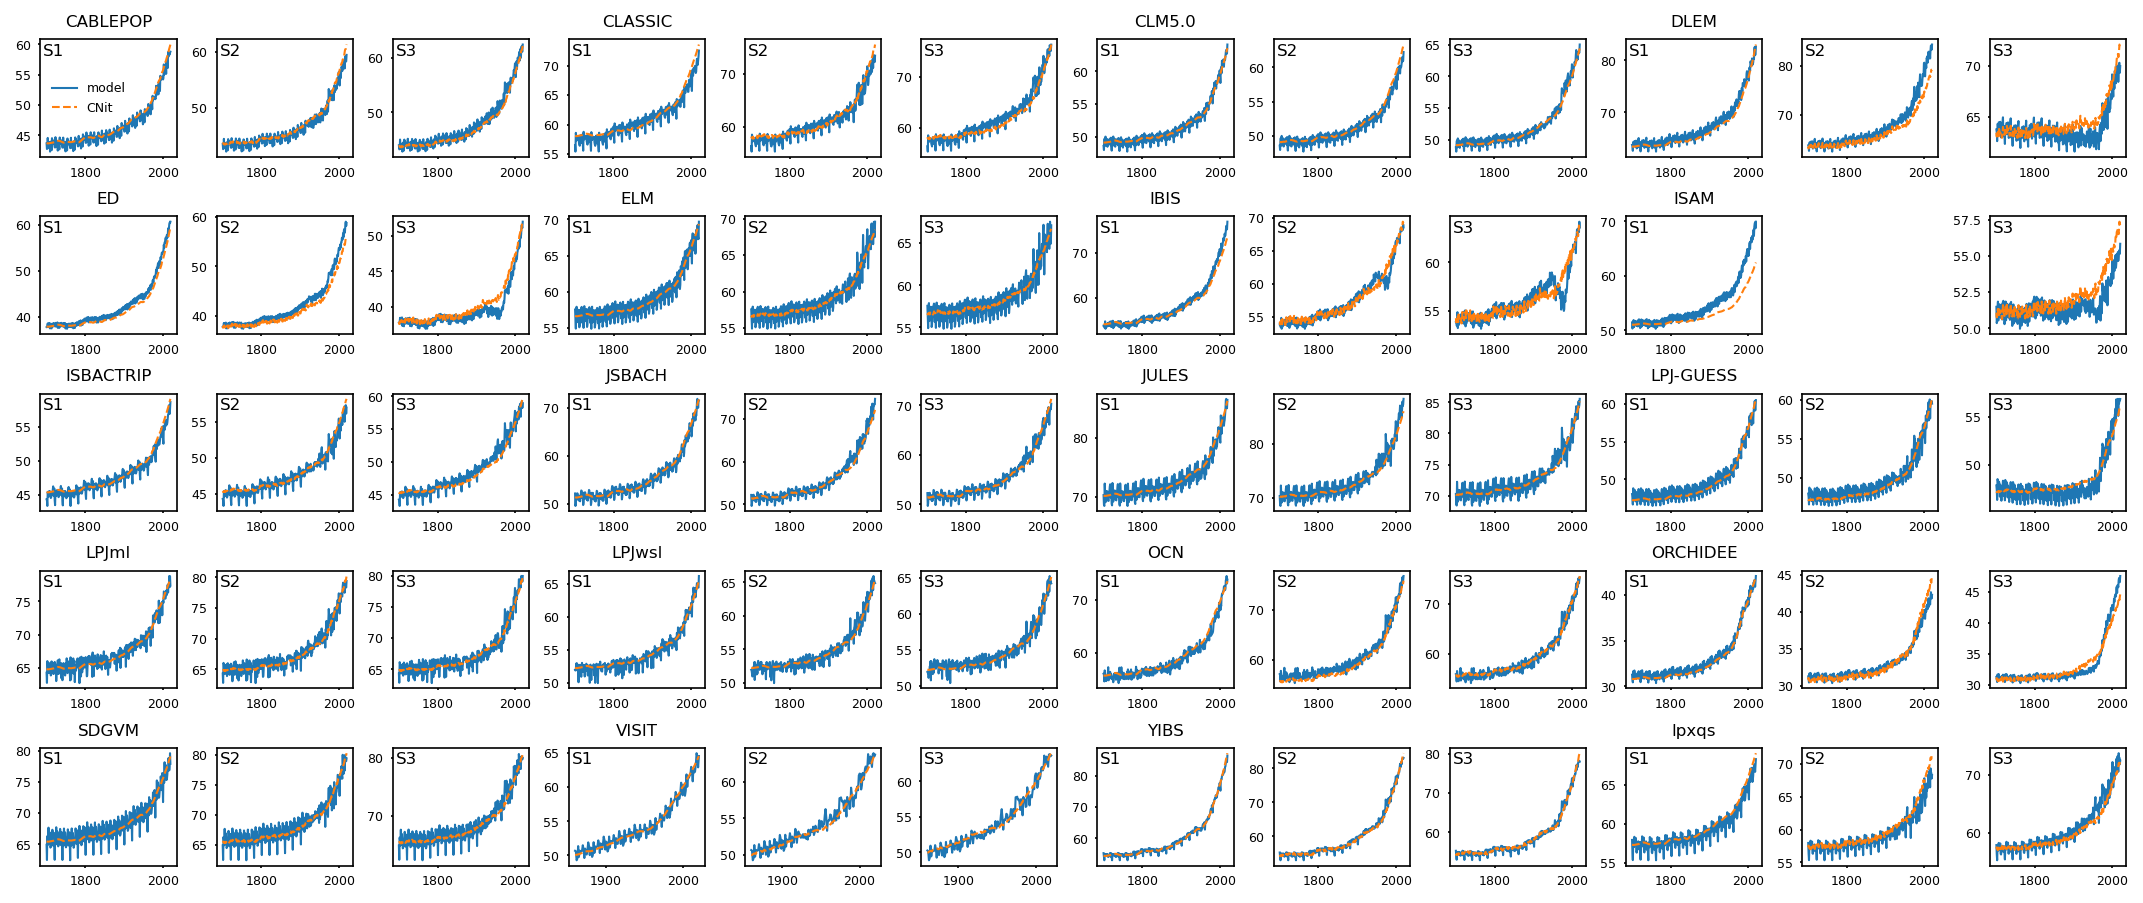

In [15]:
var = "CflxNPP"

fig, axs = plt.subplots(
    n_rows, n_cols, figsize=(3 * n_cols / 2.54, 3 * n_rows / 2.54), squeeze=False
)

for idx, mdl in enumerate(mdl_list):
    row = idx // n_model_per_row
    col_start = (idx % n_model_per_row) * len(experiments)
    axs_row = axs[row, col_start : col_start + len(experiments)]
    plot_single_model(axs_row, var, mdl)

axs[0, 0].legend(["model", "CNit"], frameon=0, loc="center left")

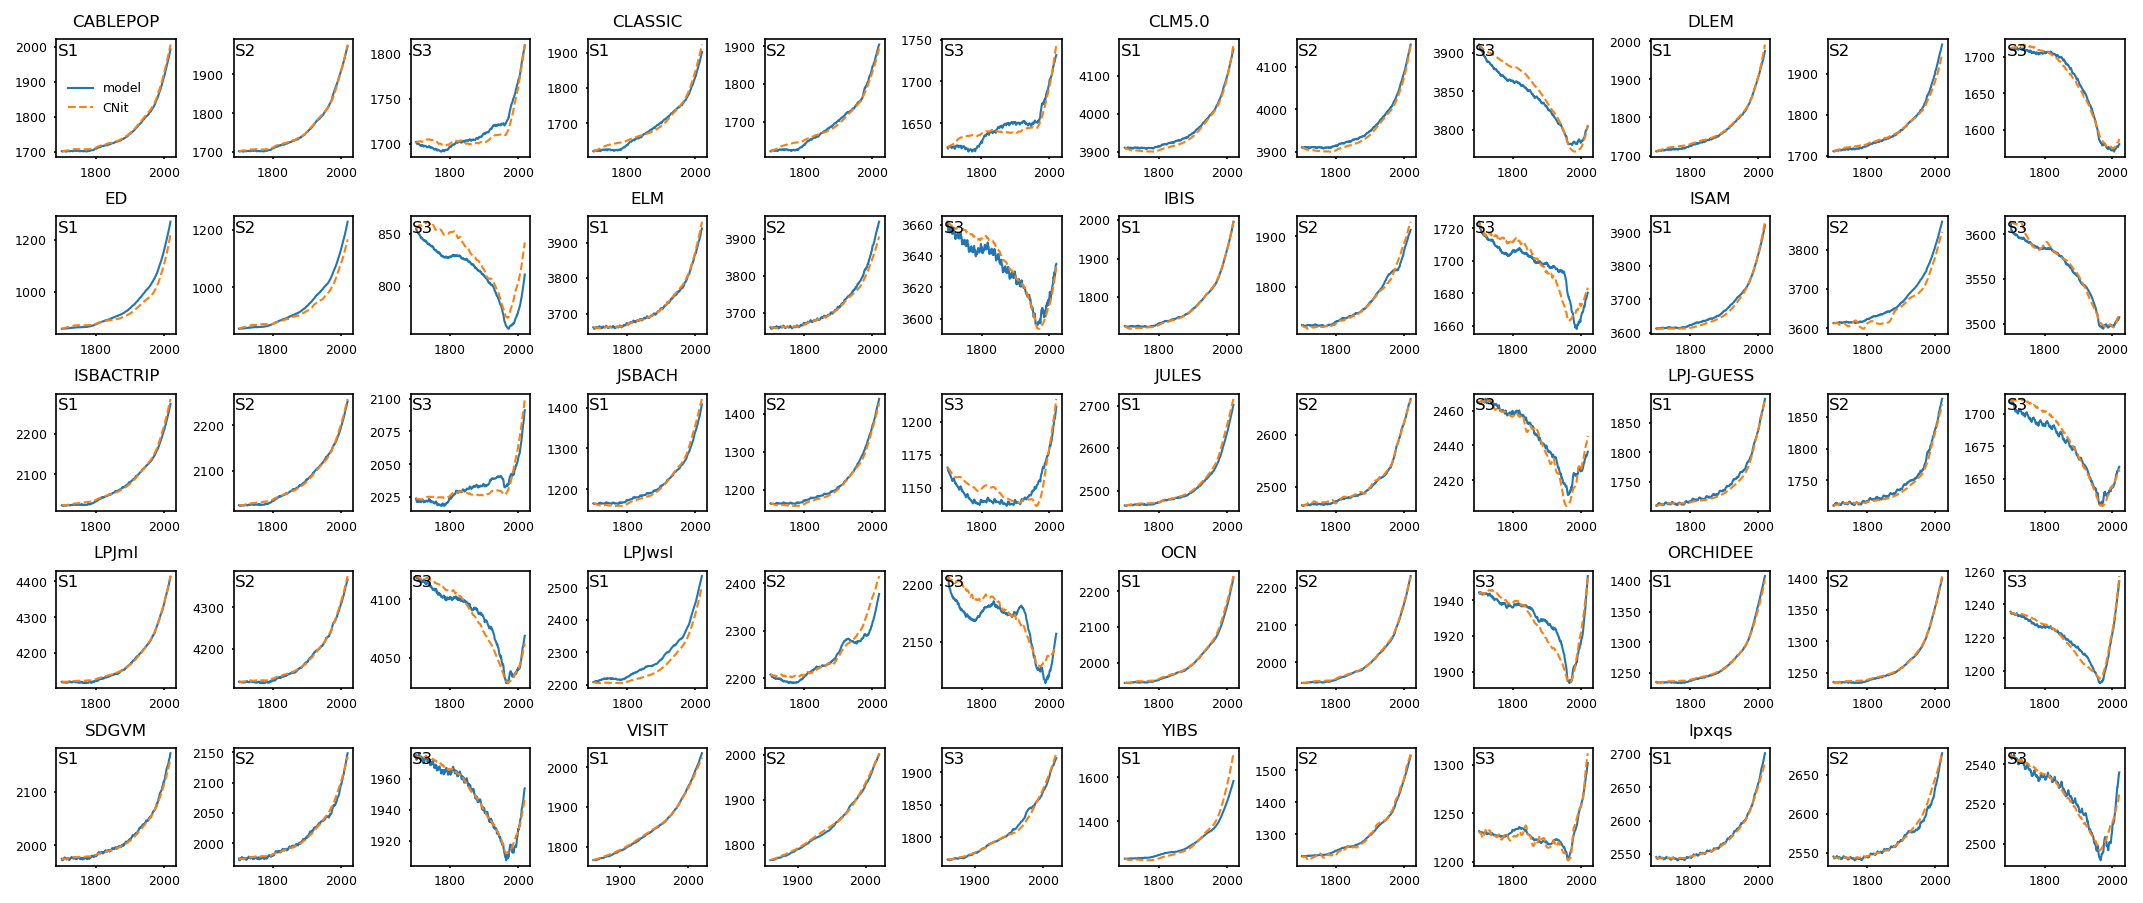

In [16]:
var = "CplsPLS"

fig, axs = plt.subplots(
    n_rows, n_cols, figsize=(3 * n_cols / 2.54, 3 * n_rows / 2.54), squeeze=False
)

for idx, mdl in enumerate(mdl_list):
    row = idx // n_model_per_row
    col_start = (idx % n_model_per_row) * len(experiments)
    axs_row = axs[row, col_start : col_start + len(experiments)]
    plot_single_model(axs_row, var, mdl)

axs[0, 0].legend(["model", "CNit"], frameon=0, loc="center left")

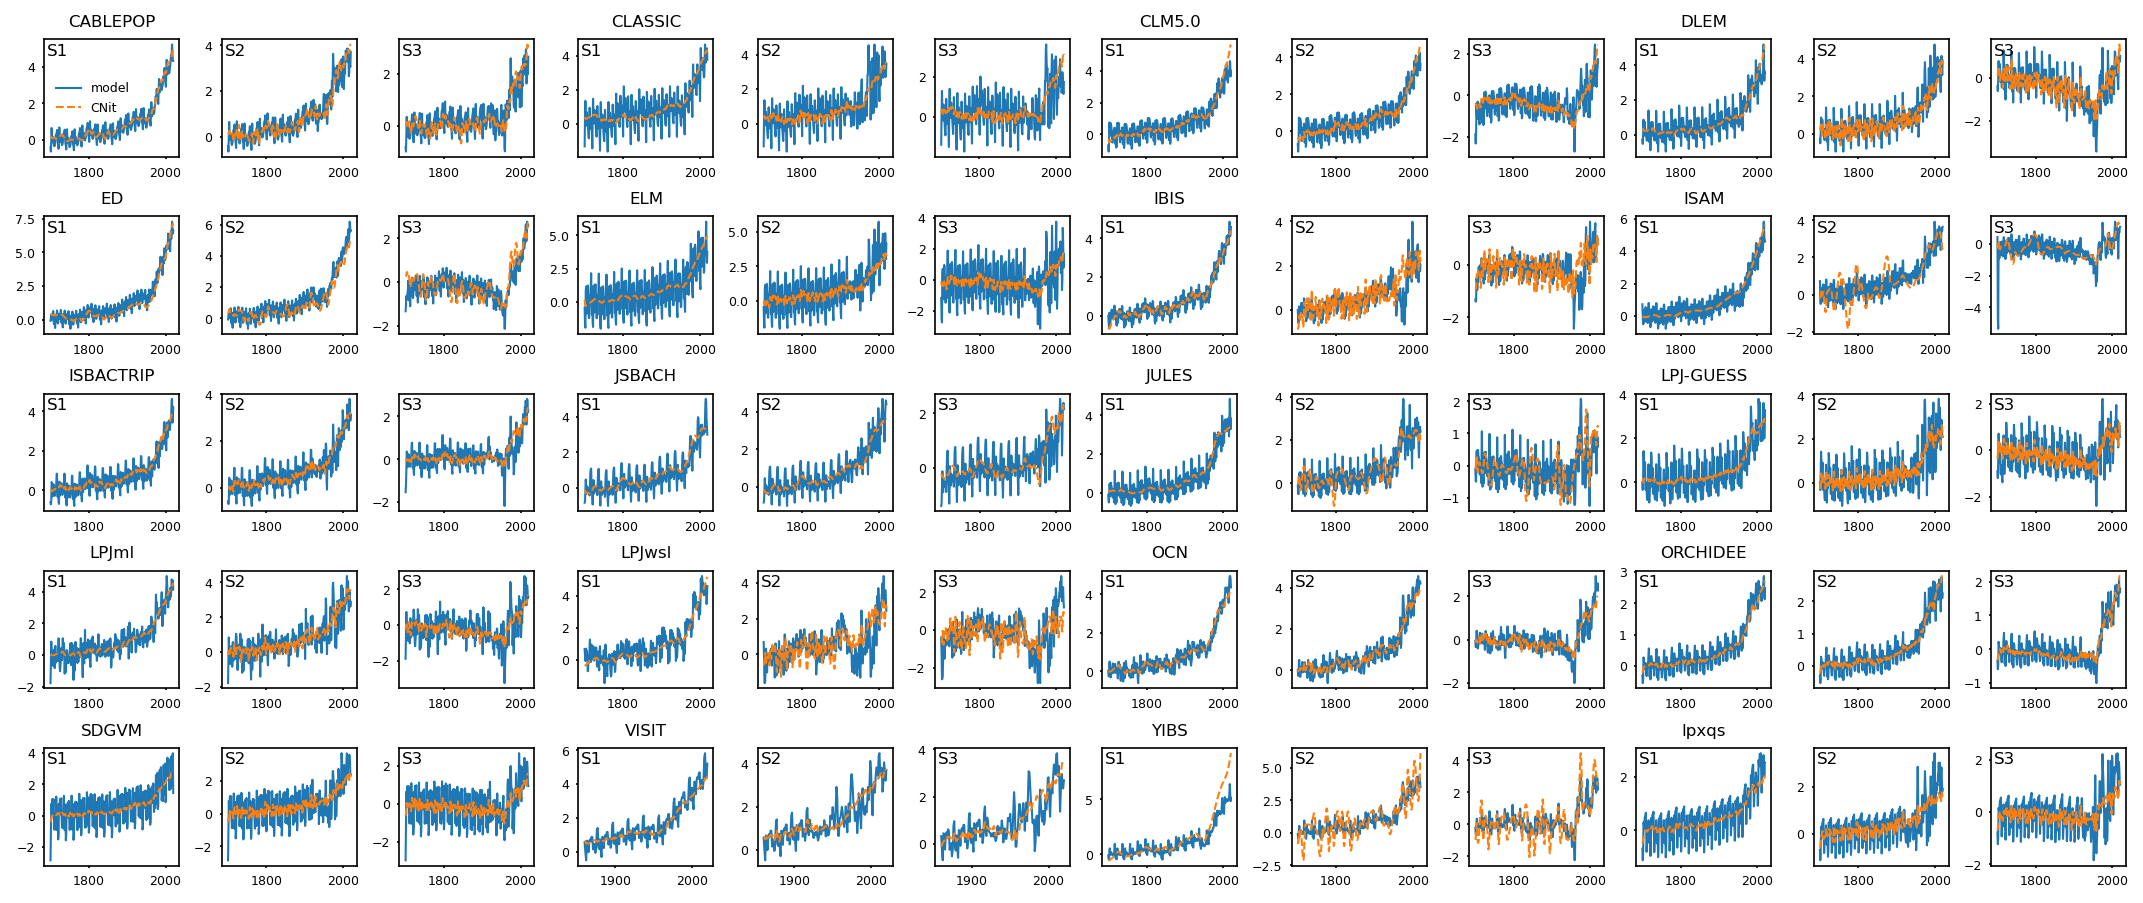

In [17]:
var = "CflxNetPLS"

fig, axs = plt.subplots(
    n_rows, n_cols, figsize=(3 * n_cols / 2.54, 3 * n_rows / 2.54), squeeze=False
)

for idx, mdl in enumerate(mdl_list):
    row = idx // n_model_per_row
    col_start = (idx % n_model_per_row) * len(experiments)
    axs_row = axs[row, col_start : col_start + len(experiments)]
    plot_single_model(axs_row, var, mdl)

axs[0, 0].legend(["model", "CNit"], frameon=0, loc="center left")

# Run additional experiments

After calibration, CNit can run additional experiments that the original DGVMs
may not have simulated. Here we double historical warming in an S3 forcing series
to examine the carbon-cycle response.

In [18]:
cnit_cable = CNitModel.from_config(mdl_cfg_by_mdl["CABLEPOP"])

In [19]:
exp_forcing = forcing_data.sel(exp="S3").fillna(0)

exp_cfg = CNitExpConfig(
    name="S3_double_warming",
    switch_N=mdl_cfg_by_mdl["CABLEPOP"].switch_N,
    time_axis=Q(exp_forcing["time"].data, exp_forcing["time"].unit),
    dT_s=Q(exp_forcing["dT"].data * 2, exp_forcing["dT"].unit),
    CO2_s=Q(exp_forcing["CO2"].data, exp_forcing["CO2"].unit),
    CemsLUnet_s=Q(exp_forcing["CemsLUnet"].data, exp_forcing["CemsLUnet"].unit),
    CemsLUgrs_s=Q(exp_forcing["CemsLUgrs"].data, exp_forcing["CemsLUgrs"].unit),
    NflxAD_s=Q(exp_forcing["NflxAD"].data, exp_forcing["NflxAD"].unit),
    NflxFT_s=Q(exp_forcing["NflxFT"].data, exp_forcing["NflxFT"].unit),
    NemsLUnet_s=Q(exp_forcing["NemsLUnet"].data, exp_forcing["NemsLUnet"].unit),
    NemsLUgrs_s=Q(exp_forcing["NemsLUgrs"].data, exp_forcing["NemsLUgrs"].unit),
    NemsLUmin_s=Q(exp_forcing["NemsLUmin"].data, exp_forcing["NemsLUmin"].unit),
)

In [20]:
res_s3_double_warming = cnit_cable.run_experiments([exp_cfg])

In [21]:
res_s3_double_warming = res_s3_double_warming.sel(experiment="S3_double_warming")
res_s3 = res_ds.sel(model="CABLEPOP", experiment="S3")

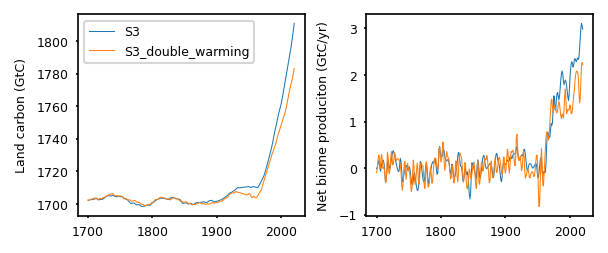

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(10 / 2.54, 4 / 2.54))

axs[0].plot(time, res_s3["CplsPLS"], label="S3")
axs[0].plot(time, res_s3_double_warming["CplsPLS"], label="S3_double_warming")
axs[0].set_ylabel("Land carbon (GtC)")

axs[1].plot(time, res_s3["CflxNetPLS"], label="S3")
axs[1].plot(time, res_s3_double_warming["CflxNetPLS"], label="S3_double_warming")
axs[1].set_ylabel("Net biome produciton (GtC/yr)")

axs[0].legend()